# Маркетплейс: онлайн торговля
**Условие задачи:** мы можем реализовать некий товар по двум ценам: $ price_1 = 100$, $price_2 = 200$ (в общем случае, товар может быть реализован по любой цене). При этом накладные расходы (сюда включается себестоимость, доставка, реклама и т.д.) состаляют 50. Необходимо определить цену, по которой мы получим больше прибыли. При этом спрос на товар определяется распределением Пуассона со следующими параметрами:  

- Мат. ожидание спроса (количество покупок за день) по цене 100: $order_1 = 5$
- Мат. ожидание спроса по цене 200: $order_2 = 2$

Найти оптимальную цену продажи, используя следующие стратегии:
- эпсилон жадной стратегия
- оптимизм в неопределенности
- UCB1
- выборка Томпсона

**Оценивание решения:** за каждую реализованную стратегию начисляется **5 баллов**. Также в конце необходимо написать **краткий отчет**, который оценивается в **7 баллов**. Таким образом, за рещение задачи в сумме можно получить **27 баллов**.

## Экспортируем необходимые пакеты для распределение Пуассона



In [ ]:
# from scipy.stats import poisson
import numpy as np
import matplotlib.pyplot as plt
import random
N = 120 # количество дней торговли
o1, o2 = 5, 2 # значения мат. ожидания спроса
p1, p2 = 100, 200 # цены
costs = 50 # накладные расходы

def get_reward(order, price):
    r = np.random.poisson(order, 1)
    return (r * (price - costs))

print(get_reward(o1, p1))
print(get_reward(o2, p2))

rew1 = (p1 - costs) * o1
rew2 = (p2 - costs) * o2
if rew1 > rew2:
    optim_reward = rew1
else:
    optim_reward = rew2

[150]
[450]


### Эпсилон жадная стратегия
В эпсилон жадной стратегии выбор делается на каждом шаге

In [ ]:
eps = 0.1
# eps = 0.5

t1 = [get_reward(o1, p1)] # стартовая прибыль
t2 = [get_reward(o2, p2)]

select = False # флаг для определения какую цену используем (для t2 - False, для t1 - True). Изначально выбираем цену, при которой стартовая прибыль наибольшая
if t1 > t2:
    select = True

reward = []

for i in range(N-2):
    # to-do реализовать эпсилон-жадную стратегию, записывать прибыль в t1/t2

    m1, m2 = np.mean(t1), np.mean(t2)

    if m1 > m2:
        select = True
    else:
        select = False

print('Количество дней торговли с ценой 100:', len(t1))
print('Количество дней торговли с ценой 200:', len(t2))
print('Средняя прибыль с ценой 100:', m1)
print('Средняя прибыль с ценой 200:', m2)

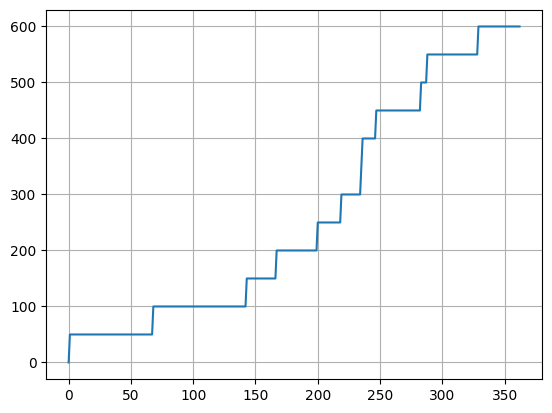

In [ ]:
opt_reward = np.ones_like(reward)*optim_reward
regret = opt_reward.cumsum() - np.cumsum(reward)
plt.plot(regret)
plt.grid(True)
#plt.plot(np.cumsum(reward))

### Оптимизм в неопределенности
В этом алгоритме присваиваем каждой руке заведомо большое значение reward. Обновляем это значение и на каждом шаге выбираем руку с большим значением reward. Будьте внимательны при расчете средней прибыли.

In [ ]:
t1 = np.array([20000])
t2 = np.array([20000])
REWARD = []

for i in range(N-2):
    # to-do реализовать стратегию оптимизма в неопределенности

print('Количество дней торговли с ценой 100:', len(t1))
print('Количество дней торговли с ценой 200:', len(t2))
print('Средняя прибыль с ценой 100:', np.mean(t1))
print('Средняя прибыль с ценой 200:', np.mean(t2))

Количество дней торговли с ценой 100: 37
Количество дней торговли с ценой 200: 83
Средняя прибыль с ценой 100: 278.3783783783784
Средняя прибыль с ценой 200: 291.56626506024094


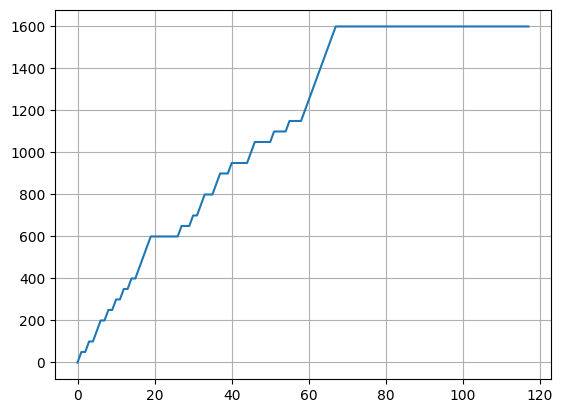

In [ ]:
opt_reward = np.ones_like(REWARD) * optim_reward
regret = opt_reward.cumsum() - np.cumsum(REWARD)
plt.plot(regret)
plt.grid(True)
# plt.plot(optim_reward.cumsum())
# plt.plot(np.cumsum(REWARD))

### UCB1
$$ a = \bar{r_j}+\sqrt{\frac{2\ln{n}}{n_j}} $$
Для USB1 необходимо перейти на интервал [0, 1]. Мы можем это сделать, но примем во внимание тот факт, что UCB1 используется в тех случаях, когда мы не знаем из какого распределения пришла случайная величина. В случае спроса, мы предположили, что это распределение Пуассона. Таким образом, нам надо определить верхнюю доверительную границу исходя из этого распределения.

В распределении Пуассона мат. ожидание $ E[Y] = \lambda$ и дисперсия $ D[Y] = \lambda$  
Необходимо определить верхнюю границу на мат. ожидание $\lambda$. Если предположить, что $E[Y] = \lambda$ это случайная величина, распределенная по нормальному закону, то
$$ D[\lambda|n] = \frac{D[Y]}{n+1} = \frac{E[Y]}{n+1} = \frac{\lambda}{n+1} $$
В итоге, верхняя доверительная граница будет определяться так:
$$ UCB = E[Y] + \sqrt{\frac{D[Y]}{n+1}} $$

Подсказка: в формуле расчета верхней границы (UCB) чего-то не хватает. Вспомните правило трех сигм и примените его при расчете.

In [ ]:
t1 = get_reward(o1, p1)
t2 = get_reward(o2, p2)
REWARD = [rew1, rew2]

for i in range(N-2):
    # to-do реализовать стратегию UCB

print('Количество дней торговли с ценой 100:', len(t1))
print('Количество дней торговли с ценой 200:', len(t2))
print('Средняя прибыль с ценой 100:', np.mean(t1))
print('Средняя прибыль с ценой 200:', np.mean(t2))

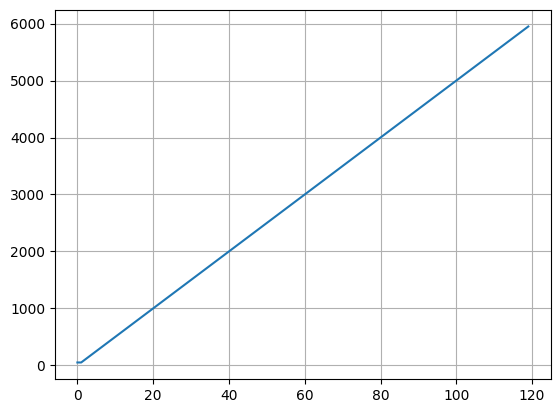

In [ ]:
opt_reward = np.ones_like(REWARD)*optim_reward
regret = opt_reward.cumsum() - np.cumsum(REWARD)
plt.plot(regret)
plt.grid(True)
#plt.plot(optim_reward.cumsum())
#plt.plot(np.cumsum(REWARD))

### Выборка Томпсона
В этом методе на каждый оцениваемый параметр строится распределение. Для выбора руки семплируем из каждого распределения и выбираем ту руку, у которой вероятность больше

177
190
228.5310734463277
292.10526315789474


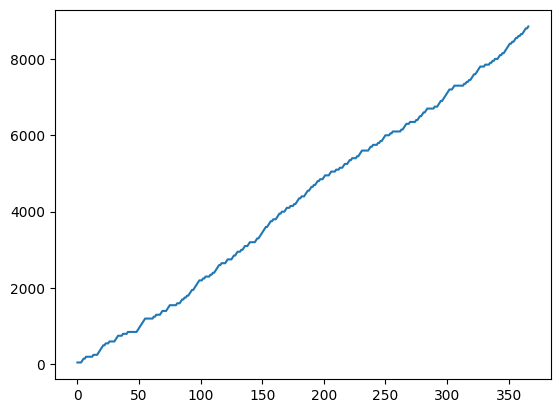

In [ ]:
from scipy.stats import poisson, gamma
alpha1,alpha2 = 4, 3
beta1,beta2 = 1, 1
t1, t2 = get_reward(o1, p1), get_reward(o2, p2)

def density(t1, alpha1, beta1):
    alpha1 += t1
    beta1 += 1
    return gamma(alpha1,scale=1/beta1), alpha1, beta1

rv1, alpha1, beta1 = density(t1,alpha1, beta1)
rv2, alpha2, beta2 = density(t2,alpha2, beta2)


REWARD = [rew1, rew2]
N = 365
for i in range(N):


# print(REWARD)
opt_reward = np.ones_like(REWARD)*optim_reward
regret = opt_reward.cumsum() - np.cumsum(REWARD)
plt.plot(regret)
print(len(t1))
print(len(t2))
print(np.mean(t1))
print(np.mean(t2))

In [ ]:
def plot_dens(alpha, beta):

    # Создание объекта случайной величины бета-распределения
    rv = gamma(alpha, scale=1/beta)
    # Генерация выборки из гамма-распределения
    s = 1000
    sample = rv.rvs(size=s)

    # Построение гистограммы выборки
    #plt.hist(sample, bins=50, density=True, alpha=0.7, rwidth=0.85, color='skyblue')

    # Построение графика плотности вероятности
    x = np.linspace(0, 500, 1000)
    y = rv.pdf(x)
    eps = 10**-7
    b = y>eps
    plt.plot(x[b], rv.pdf(x[b]), 'k-', lw=2)

    # Отображение графика
    plt.xlabel('Значение')
    plt.ylabel('Плотность вероятности')
    plt.title('Гамма-распределение (alpha={}, beta={})'.format(alpha, beta))
    plt.grid(True)
    plt.show()

plot_dens(alpha1,beta1)


plot_dens(alpha2,beta2)

In [ ]:
import numpy as np
from scipy.stats import gamma

# Априорные параметры Гамма-распределения
alpha = 2
beta = 1

# Выборка наблюдений из распределения Пуассона
obs = np.array([1, 3, 2, 4, 1])

# Обновление апостериорных параметров
post_alpha = alpha + np.sum(obs)
post_beta = beta + len(obs)

# Апостериорное Гамма-распределение
posterior = gamma(post_alpha, scale=1/post_beta)

# Вывод результатов
print("Апостериорные параметры: alpha = {}, beta = {}".format(post_alpha, post_beta))
print("Среднее апостериорного распределения: {}".format(posterior.mean()))

# Построение графика плотности вероятности апостериорного распределения
x = np.linspace(0, 10, 1000)
y = posterior.pdf(x)
plt.plot(x, y)
plt.title("Плотность вероятности апостериорного распределения")
plt.xlabel("Значение параметра")
plt.ylabel("Плотность вероятности")
plt.show()

### Выводы:

Напишите отчет об использованных стратегиях. Какая из них лучше и почему? Где еще можно применить многоруких бандитов и т.д.?